# IVSN auf eigenem Bild: Attention Map + Scanpath Overlay

Läuft ein eigenes Search Image + Target Image durch IVSN (Zhang et al. 2018), genau wie auf den Waldo/NaturalDesign-Datensätzen in `vs_saccade_exp/runExp.py`. Liefert die Attention Map und den Scanpath, jeweils als Overlay auf dem Search Image.

In [34]:
import sys, os, pathlib
sys.path.insert(0, os.path.abspath(".."))

_cwd = pathlib.Path.cwd().resolve()
repo_root = next(p for p in [_cwd] + list(_cwd.parents) if (p / "vs_model").is_dir())
sys.path.insert(0, str(repo_root))

import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

from vs_model import VisualSearchModel

## 1. Eigene Bilder angeben

- `SEARCH_IMG_PATH`: dein Suchbild (wird auf 896x736 resized, also am besten vorher auf ein ähnliches Seitenverhältnis zuschneiden, sonst wird es verzerrt).
- `TARGET_IMG_PATH`: ein Crop/Ausschnitt des Zielobjekts aus dem Suchbild (wird auf 32x32 resized).
- `GT_MASK_PATH`: optional. Ein Bild in Suchbild-Auflösung mit einer weißen (255) Box an der Zielposition, sonst schwarz. Wenn `None`, wird automatisch eine leere (komplett schwarze) Dummy-Maske erzeugt — die Suche bricht dann nie vorzeitig ab, sondern läuft alle `NumFix` Fixationen durch.

In [35]:
data_dir = repo_root / "notebooks" / "stimuli"
SEARCH_IMG_PATH = str(data_dir / "lung.png" )   # eigenes Bild hier eintragen
TARGET_IMG_PATH = str(data_dir / "target.png")
GT_MASK_PATH = str(data_dir / "mask.png")

In [36]:
from IPython.display import display

_STIM_SIZE = (896, 736)  # (width, height), entspricht stim_shape unten
_TAR_SIZE = (32, 32)     # (width, height), entspricht tar_shape unten

search_img_resized = Image.open(SEARCH_IMG_PATH).convert("RGB").resize(_STIM_SIZE)
target_img_resized = Image.open(TARGET_IMG_PATH).convert("RGB").resize(_TAR_SIZE)

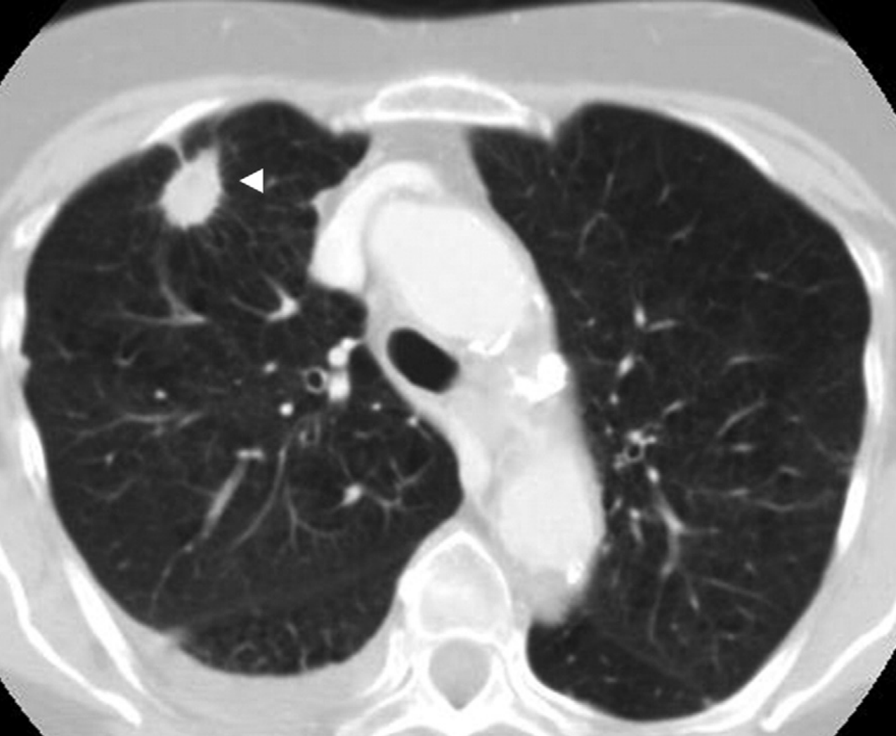

In [37]:
display(search_img_resized)

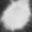

In [38]:
display(target_img_resized)

## 2. Modell- und Experiment-Konfiguration

Referenzwerte aus `vs_saccade_exp/data_utils.py:get_exp_info("NaturalDesign")` — dieselbe Konfiguration, mit der IVSN im Repo auf natürliche Szenenbilder angewendet wird.

In [39]:
VGG_MODEL_PATH = os.path.abspath("../pretrained_model/vgg16_imagenet_filters.h5")

eccParam = {
    'rf_min': [2] * 5,
    'stride': [2] * 5,
    'ecc_slope': [0, 0, 3.5 * 0.02, 8 * 0.02, 16 * 0.02],
    'deg2px': [round(30.0), round(30.0 / 2), round(30.0 / 4), round(30.0 / 8), round(30.0 / 16)],
    'fovea_size': 4,
    'rf_quant': 1,
    'pool_type': 'avg',
}

model_desc = {
    'eccParam': eccParam,
    'ecc_depth': 0,          # 0 => IVSN (plain VGG16, no eccentricity pooling)
    'out_layer': [1, 1, 1],
    'comp_layer': 'diff',
    'vgg_model_path': VGG_MODEL_PATH,
    'model_subname': '',
}

eye_res = 736
stim_shape = (736, 896, 3)   # (height, width, channels)
tar_shape = (32, 32, 3)
ior_size = 2 * tar_shape[0]
NumFix = 66

exp_info = {
    'eye_res': eye_res,
    'stim_shape': stim_shape,
    'tar_shape': tar_shape,
    'ior_size': ior_size,
    'NumStimuli': 1,
    'NumFix': NumFix,
    'gt_mask': None,
    'fix': None,
    'bg_value': 0,
    'rev_img_flag': 0,
    'deg2px': 30,
    'weight_pattern': 'l',
    'dog_size': [[3, 0], [5, 1]],
    's_ratio': None,
}

## 3. Modell laden

In [40]:
corner_bias = 16 * 4

vsm = VisualSearchModel(model_desc)
vsm.load_exp_info(exp_info, corner_bias=corner_bias)
print(vsm.model_name)

IVSN_1_1_1


## 4. Ground-Truth-Maske vorbereiten (Dummy falls keine angegeben)

In [41]:
if GT_MASK_PATH is None:
    dummy_gt = np.zeros((stim_shape[0], stim_shape[1]), dtype=np.uint8)
    GT_MASK_PATH = "/tmp/ivsn_dummy_gt_mask.png"
    cv2.imwrite(GT_MASK_PATH, dummy_gt)
    print(f"Dummy-GT-Maske geschrieben nach {GT_MASK_PATH}")

## 5. Suche durchführen

In [42]:
saccade, attn_maps, vis_area_crop, layer_maps = vsm.start_search(
    SEARCH_IMG_PATH, TARGET_IMG_PATH, GT_MASK_PATH, debug_flag=True
)
print(f"Anzahl Fixationen: {len(saccade)}")
print(saccade)

1/1 [==============================] - 0s 88ms/step


2026-10-08 16:25:13.261211: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-08 16:25:13.393069: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 0s 13ms/step
Anzahl Fixationen: 5
[[368 448]
 [352 320]
 [304 272]
 [480 336]
 [176 240]]


## 6. Attention-Map-Overlay

/var/folders/rk/wq2f41314mq0v72wwsm3phkw0000gn/T/ipykernel_75545/3967363377.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  heatmap = Image.fromarray((rgba[:, :, :3] * 255).astype(np.uint8), mode="RGB").resize(base_img.size)


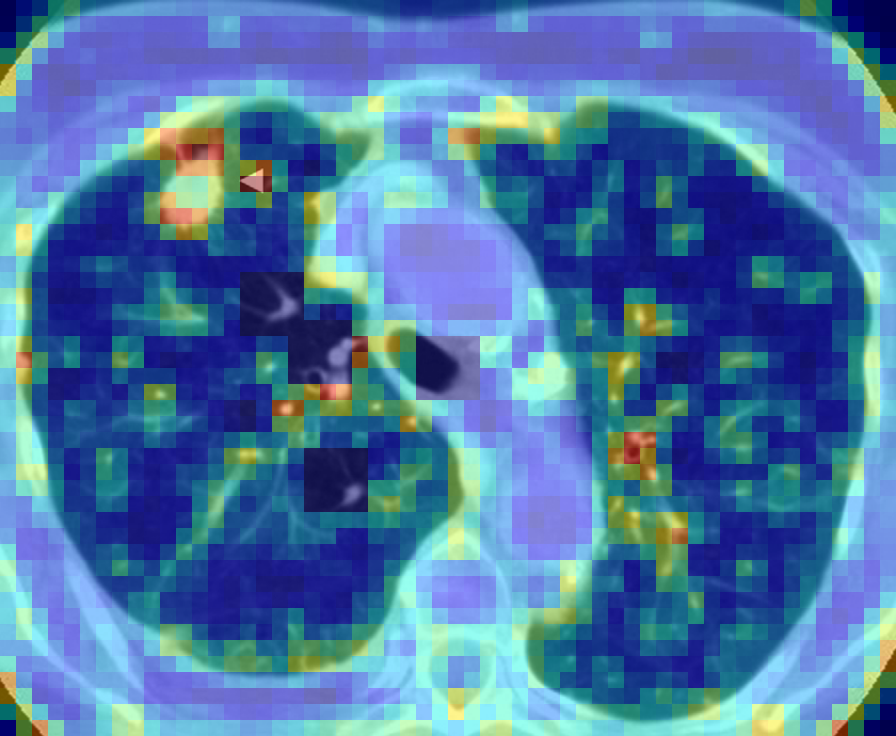

In [43]:
def crop_attn_to_stimulus(attn_map, fixation_rc, eye_res, corner_bias, stim_shape):
    """attn_map is in the model's padded square canvas (model_ip_shape); this
    crops out only the sub-region that actually corresponds to the stimulus
    image (removing the surrounding padding), so it aligns 1:1 with the
    original search image before resizing."""
    row_start = int(round(eye_res + corner_bias - fixation_rc[0]))
    col_start = int(round(eye_res + corner_bias - fixation_rc[1]))
    return attn_map[row_start:row_start + stim_shape[0], col_start:col_start + stim_shape[1]]

def make_attention_overlay(base_img, attn_map, alpha=0.45):
    attn = attn_map.astype(np.float32)
    mn, mx = attn.min(), attn.max()
    attn_norm = np.zeros_like(attn) if mx <= mn else (attn - mn) / (mx - mn)
    cmap = plt.get_cmap("jet")
    rgba = cmap(attn_norm)
    heatmap = Image.fromarray((rgba[:, :, :3] * 255).astype(np.uint8), mode="RGB").resize(base_img.size)
    return Image.blend(base_img.convert("RGB"), heatmap, alpha=alpha)

search_img = search_img_resized

# attn_maps[-1] was generated centered on the second-to-last fixation (saccade[-2])
attn_cropped = crop_attn_to_stimulus(attn_maps[-1], saccade[-2], eye_res, corner_bias, stim_shape)

last_attn_overlay = make_attention_overlay(search_img, attn_cropped)
display(last_attn_overlay)

## 7. Scanpath-Overlay

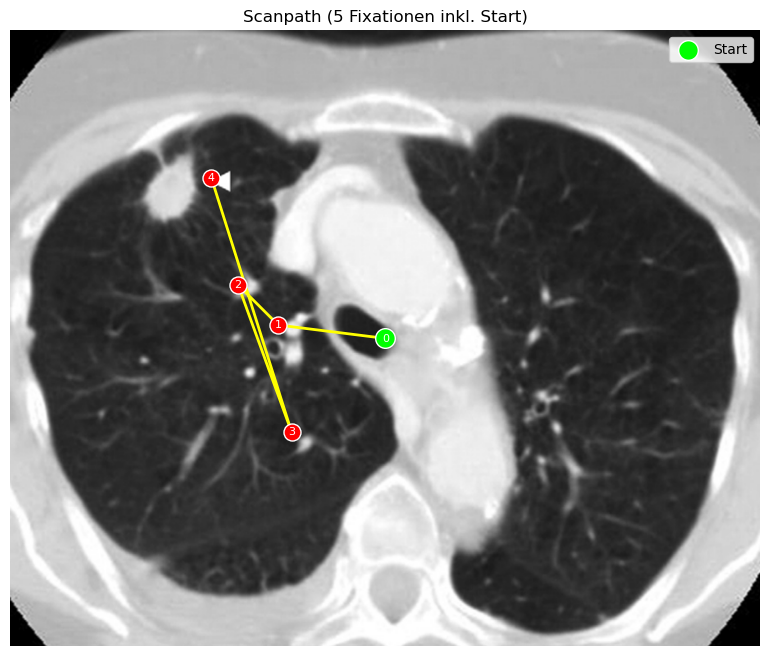

In [46]:
search_img_arr = np.array(search_img)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(search_img_arr)
ax.plot(saccade[:, 1], saccade[:, 0], '-', color='yellow', lw=2)
ax.scatter(saccade[:, 1], saccade[:, 0], s=150, c='red', edgecolors='white', zorder=3)
ax.scatter(saccade[0, 1], saccade[0, 0], s=200, c='lime', edgecolors='white', zorder=4, label='Start')
for i, (r, c) in enumerate(saccade):
    ax.text(c, r, str(i), color='white', ha='center', va='center', fontsize=8, zorder=5)
ax.legend(loc='upper right')
ax.axis('off')
ax.set_title(f"Scanpath ({len(saccade)} Fixationen inkl. Start)")
plt.show()

## 8. Kombinierte Ansicht

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
for ax, img, title in zip(
    axs,
    [search_img, last_attn_overlay],
    ["Search Image", "Attention Overlay"],
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.show()